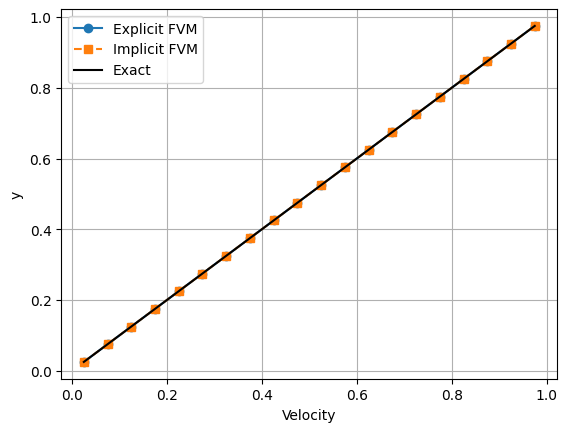

Explicit Fo = 0.2999625046869141
Implicit Fo = 3.999999999999999
Explicit steady error = 1.6451983109178059e-09
Implicit steady error = 4.4005316057749155e-09


In [4]:
import numpy as np
import matplotlib.pyplot as plt

H = 1.0
U_bottom = 0.0
U_top = 1.0
nu = 0.01
N = 20

dy = H / N
y = (np.arange(N) + 0.5) * dy

t_end = 200.0

dt_exp = 0.3 * dy**2 / nu
steps_exp = int(np.ceil(t_end / dt_exp))
dt_exp = t_end / steps_exp
Fo_exp = nu * dt_exp / dy**2

u_exp = np.zeros(N)

for n in range(steps_exp):
    old = u_exp.copy()

    u_exp[1:-1] = old[1:-1] + Fo_exp * (
        old[2:] - 2.0 * old[1:-1] + old[:-2]
    )

    u_exp[0] = old[0] + Fo_exp * (
        old[1] - 3.0 * old[0] + 2.0 * U_bottom
    )

    u_exp[-1] = old[-1] + Fo_exp * (
        old[-2] - 3.0 * old[-1] + 2.0 * U_top
    )

dt_imp = 1.0
steps_imp = int(np.ceil(t_end / dt_imp))
dt_imp = t_end / steps_imp
Fo_imp = nu * dt_imp / dy**2

A = np.zeros((N, N))

for i in range(N):
    if i == 0:
        A[i, i] = 1.0 + 3.0 * Fo_imp
        A[i, i + 1] = -Fo_imp
    elif i == N - 1:
        A[i, i] = 1.0 + 3.0 * Fo_imp
        A[i, i - 1] = -Fo_imp
    else:
        A[i, i] = 1.0 + 2.0 * Fo_imp
        A[i, i - 1] = -Fo_imp
        A[i, i + 1] = -Fo_imp

u_imp = np.zeros(N)

for n in range(steps_imp):
    b = u_imp.copy()
    b[0] += 2.0 * Fo_imp * U_bottom
    b[-1] += 2.0 * Fo_imp * U_top
    u_imp = np.linalg.solve(A, b)

u_exact = U_bottom + (U_top - U_bottom) * y / H

plt.plot(u_exp, y, "o-", label="Explicit FVM")
plt.plot(u_imp, y, "s--", label="Implicit FVM")
plt.plot(u_exact, y, "k-", label="Exact")
plt.xlabel("Velocity")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

print("Explicit Fo =", Fo_exp)
print("Implicit Fo =", Fo_imp)
print("Explicit steady error =", np.max(np.abs(u_exp - u_exact)))
print("Implicit steady error =", np.max(np.abs(u_imp - u_exact)))


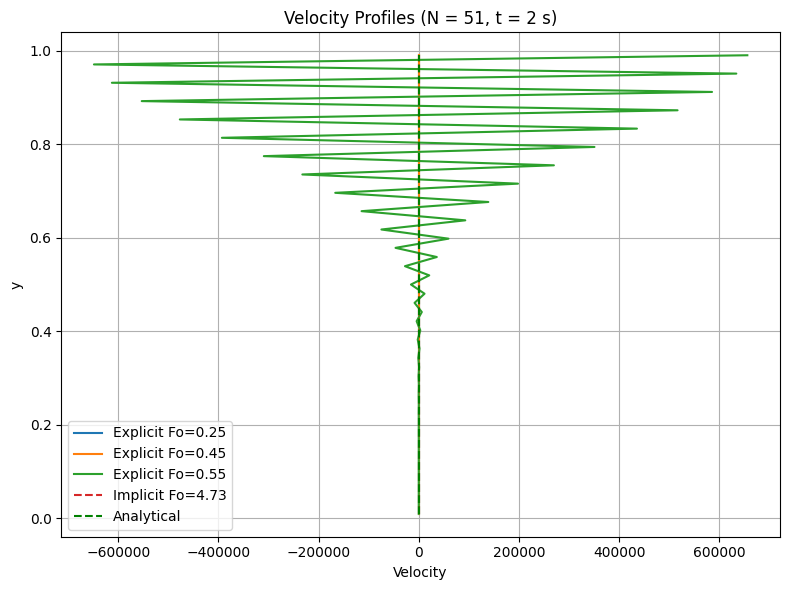

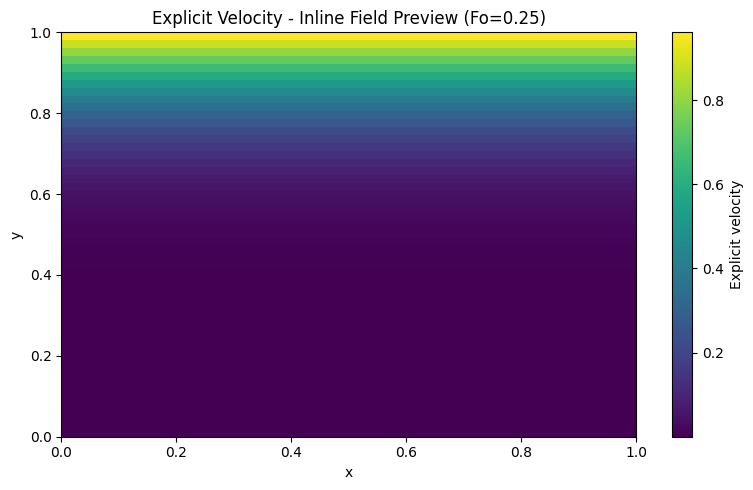

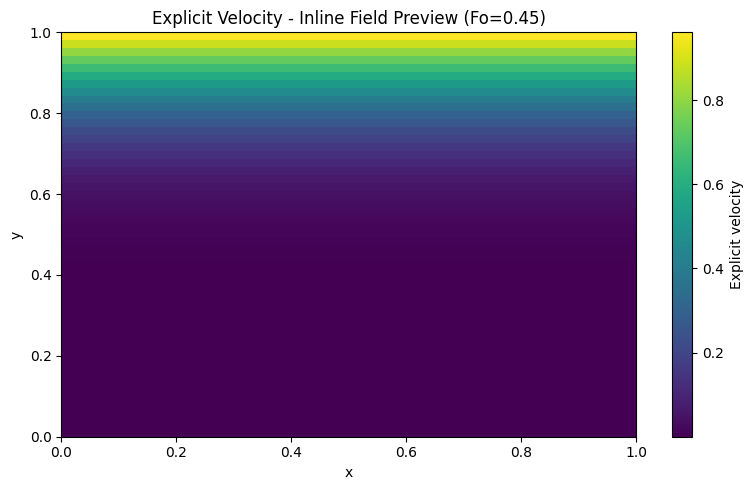

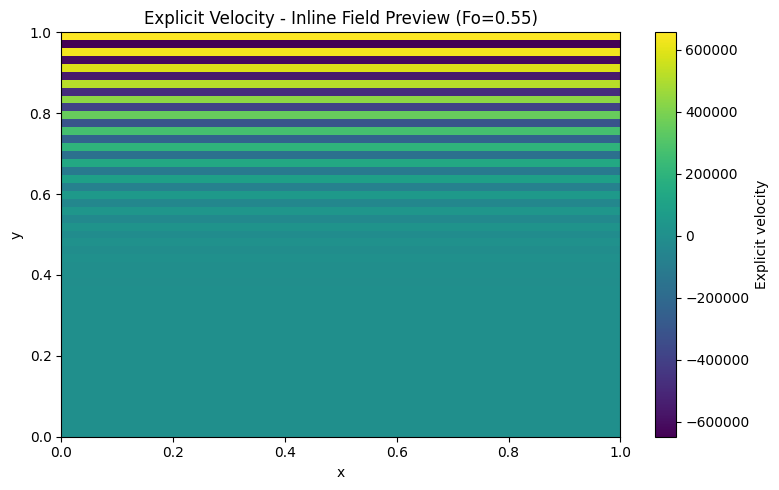

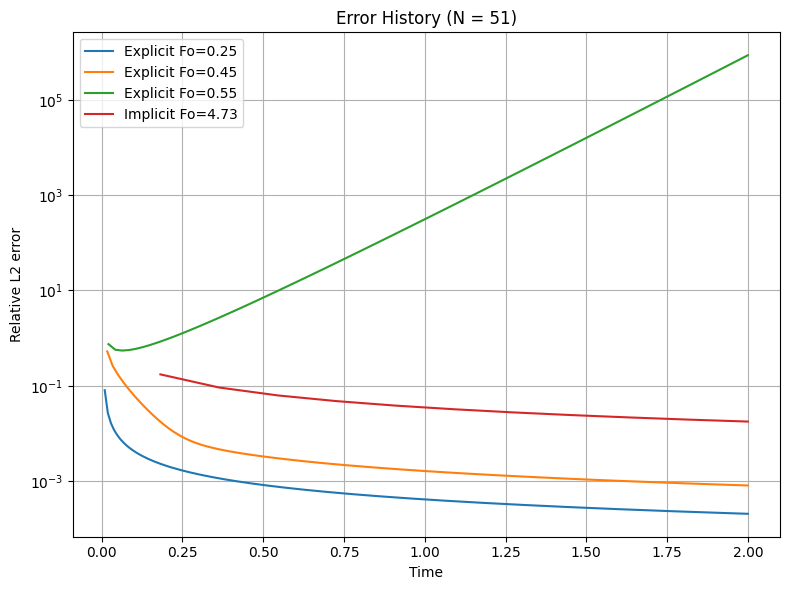


RESULTS FOR N = 51
-----------------------------------------------------------------
Grid cells: 51
Grid spacing: 0.0196078431372549
Viscosity: 0.01
Final time: 2.0
Implicit actual Fo: 4.729090909090909
Implicit final relative L2 error: 1.770339e-02

Explicit Fourier number results:
Target Fo=0.25, actual Fo=0.248900, dt=9.569378e-03, final recorded time=2.00000, last relative L2 error=2.050452e-04
Target Fo=0.45, actual Fo=0.448448, dt=1.724138e-02, final recorded time=2.00000, last relative L2 error=8.063969e-04
Target Fo=0.55, actual Fo=0.547579, dt=2.105263e-02, final recorded time=2.00000, last relative L2 error=8.677612e+05


In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters from the PDF
H = 1.0
U_bottom = 0.0
U_top = 1.0
nu = 0.01
N = 51
t_end = 2.0

Fo_exp_values = [0.25, 0.45, 0.55]
Fo_imp_target = 5.0

dy = H / N
y = (np.arange(N) + 0.5) * dy


def exact_solution(y, t, terms=300):
    u = U_bottom + (U_top - U_bottom) * y / H

    for m in range(1, terms + 1):
        u += (
            2 * U_top / (m * np.pi)
            * (-1)**m
            * np.sin(m * np.pi * y / H)
            * np.exp(-nu * (m * np.pi / H)**2 * t)
        )
    return u


def rel_l2(u, exact):
    return np.linalg.norm(u - exact) / max(
        np.linalg.norm(exact), 1e-14
    )


def explicit_solver(Fo_target):
    dt_trial = Fo_target * dy**2 / nu
    steps = int(np.ceil(t_end / dt_trial))
    dt = t_end / steps
    Fo = nu * dt / dy**2

    u = np.zeros(N)
    times = [0.0]
    errors = [rel_l2(u, exact_solution(y, 0.0))]

    for n in range(steps):
        old = u.copy()

        u[1:-1] = old[1:-1] + Fo * (
            old[2:] - 2*old[1:-1] + old[:-2]
        )
        u[0] = old[0] + Fo * (
            old[1] - 3*old[0] + 2*U_bottom
        )
        u[-1] = old[-1] + Fo * (
            old[-2] - 3*old[-1] + 2*U_top
        )

        t = (n + 1) * dt

        if not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 1e100:
            print(f"Fo={Fo_target}: unstable; stopped at t={t:.5f} s")
            break

        times.append(t)
        errors.append(rel_l2(u, exact_solution(y, t)))

    return u, np.array(times), np.array(errors), dt, Fo


def implicit_solver():
    dt_trial = Fo_imp_target * dy**2 / nu
    steps = int(np.ceil(t_end / dt_trial))
    dt = t_end / steps
    Fo = nu * dt / dy**2

    A = np.zeros((N, N))

    for i in range(N):
        A[i, i] = 1 + (3 if i == 0 or i == N-1 else 2)*Fo
        if i > 0:
            A[i, i-1] = -Fo
        if i < N-1:
            A[i, i+1] = -Fo

    u = np.zeros(N)
    times = [0.0]
    errors = [rel_l2(u, exact_solution(y, 0.0))]

    for n in range(steps):
        b = u.copy()
        b[0] += 2*Fo*U_bottom
        b[-1] += 2*Fo*U_top
        u = np.linalg.solve(A, b)

        t = (n+1)*dt
        times.append(t)
        errors.append(rel_l2(u, exact_solution(y, t)))

    return u, np.array(times), np.array(errors), dt, Fo


# Run all cases
exp_results = {
    Fo: explicit_solver(Fo) for Fo in Fo_exp_values
}
u_imp, t_imp, err_imp, dt_imp, Fo_imp = implicit_solver()

u_exact_final = exact_solution(y, t_end)


# ==================================================
# GRAPH 1: VELOCITY PROFILES — PDF STYLE
# ==================================================
plt.figure(figsize=(8, 6))

for Fo in [0.25, 0.45, 0.55]:
    u, times, errors, dt, Fo_actual = exp_results[Fo]
    if np.all(np.isfinite(u)) and np.max(np.abs(u)) < 1e100:
        plt.plot(u, y, label=f"Explicit Fo={Fo}")

plt.plot(u_imp, y, "--", label=f"Implicit Fo={Fo_imp:.2f}")
plt.plot(u_exact_final, y, "g--", label="Analytical")

plt.xlabel("Velocity")
plt.ylabel("y")
plt.title("Velocity Profiles (N = 51, t = 2 s)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 2: INLINE VELOCITY FIELD PREVIEW
# ==================================================
for Fo in [0.25, 0.45, 0.55]:
    u, times, errors, dt, Fo_actual = exp_results[Fo]

    if not np.all(np.isfinite(u)) or np.max(np.abs(u)) > 1e100:
        continue

    field = np.tile(u[:, None], (1, 50))

    plt.figure(figsize=(8, 5))
    plt.imshow(
        field,
        origin="lower",
        aspect="auto",
        extent=[0, 1, 0, H],
        cmap="viridis"
    )
    plt.colorbar(label="Explicit velocity")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Explicit Velocity - Inline Field Preview (Fo={Fo})")
    plt.tight_layout()
    plt.show()


# ==================================================
# GRAPH 3: ERROR HISTORY — PDF STYLE
# ==================================================
plt.figure(figsize=(8, 6))

for Fo in [0.25, 0.45, 0.55]:
    u, times, errors, dt, Fo_actual = exp_results[Fo]

    if len(times) > 1:
        plt.semilogy(
            times[1:],
            np.maximum(errors[1:], 1e-16),
            label=f"Explicit Fo={Fo}"
        )

plt.semilogy(
    t_imp[1:],
    np.maximum(err_imp[1:], 1e-16),
    label=f"Implicit Fo={Fo_imp:.2f}"
)

plt.xlabel("Time")
plt.ylabel("Relative L2 error")
plt.title("Error History (N = 51)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ==================================================
# RESULTS TABLE
# ==================================================
print("\nRESULTS FOR N = 51")
print("-" * 65)
print("Grid cells:", N)
print("Grid spacing:", dy)
print("Viscosity:", nu)
print("Final time:", t_end)
print("Implicit actual Fo:", Fo_imp)
print("Implicit final relative L2 error:", f"{err_imp[-1]:.6e}")

print("\nExplicit Fourier number results:")
for Fo in Fo_exp_values:
    u, times, errors, dt, Fo_actual = exp_results[Fo]
    print(
        f"Target Fo={Fo:.2f}, actual Fo={Fo_actual:.6f}, "
        f"dt={dt:.6e}, final recorded time={times[-1]:.5f}, "
        f"last relative L2 error={errors[-1]:.6e}"
    )
